In [33]:
from astroquery.esa.euclid import Euclid
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

Euclid.get_status_messages()      # check the archive is up
tables = Euclid.load_tables(only_names=True, include_shared_tables=True)
names = [t.name for t in tables]
print(len(names), "tables")
print(*[n for n in names if "phz" in n.lower() or "phys" in n.lower() or "mer_catalogue" in n.lower()], sep="\n")

INFO: Retrieving tables... [astroquery.utils.tap.core]
INFO: Parsing tables... [astroquery.utils.tap.core]
INFO: Done. [astroquery.utils.tap.core]
103 tables
catalogue.mer_catalogue
catalogue.phz_classification
catalogue.phz_galaxy_sed
catalogue.phz_nir_physical_parameters
catalogue.phz_photo_z
catalogue.phz_physical_parameters
catalogue.phz_qso_physical_parameters
catalogue.phz_star_sed
catalogue.phz_star_template
q1.phz_catalogue
q1.phz_catalogue_l3
sedm.phz_catalogue
sedm.phz_catalogue_l3


INFO: Query finished. [astroquery.utils.tap.core]
1277198 galaxies


/tmp/ipykernel_1731/1620597157.py:23: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



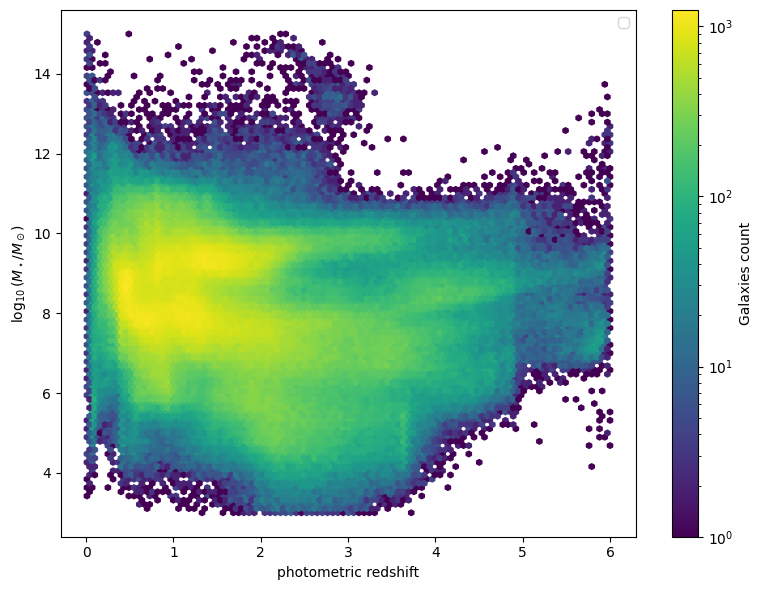

In [43]:
SAMPLE_MOD = 20
Z_MAX, M_MIN, M_MAX = 7, 3, 15
query = f"""
SELECT a.phz_median AS z, b.phz_pp_median_stellarmass AS mass
FROM catalogue.phz_photo_z AS a
JOIN catalogue.phz_physical_parameters AS b ON a.object_id = b.object_id
JOIN catalogue.phz_classification AS c ON a.object_id = c.object_id
WHERE MOD(a.object_id, {SAMPLE_MOD}) = 0
  AND a.phz_median > 0 AND a.phz_median < {Z_MAX}
  AND b.phz_pp_median_stellarmass > {M_MIN} AND b.phz_pp_median_stellarmass < {M_MAX}
"""
job = Euclid.launch_job_async(query, verbose=False)
dfg = job.get_results().to_pandas()
print(len(dfg), "galaxies")

#AND c.phz_gal_prob > 0.5

fig, ax = plt.subplots(figsize=(8, 6))
hb = ax.hexbin(dfg.z, dfg.mass, gridsize=100, bins="log", cmap="viridis", mincnt=1)
plt.colorbar(hb, label="Galaxies count")
ax.set_xlabel("photometric redshift")
ax.set_ylabel(r"$\log_{10}(M_\star / M_\odot)$")
ax.legend()
plt.tight_layout()
plt.savefig("q1_mass_vs_z_galaxies.png", dpi=200)
plt.show()